# Задание 8. Уравнение разделяющей кривой

## Imports

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 6]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Решение

In [45]:
def x2_val(x1, a):
    return (np.log(a/(1-a)) - 1 - x1**2) / (2 + x1)

def z_val(x1, x2):
    return 1 + 2 * x2 + x1 * x2 + x1**2

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

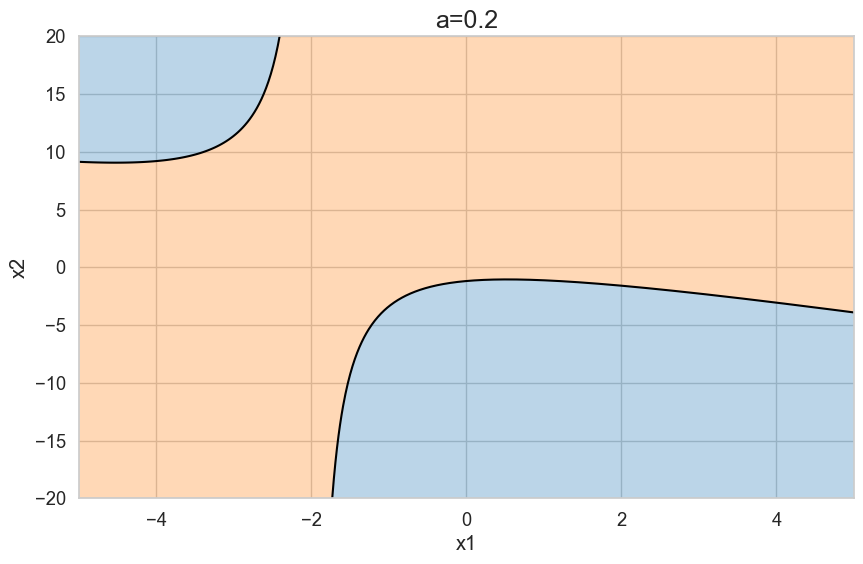

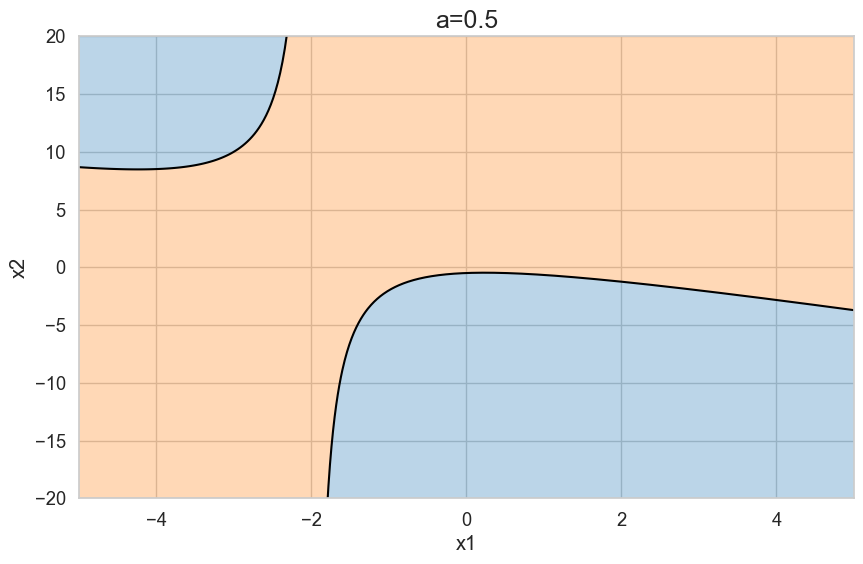

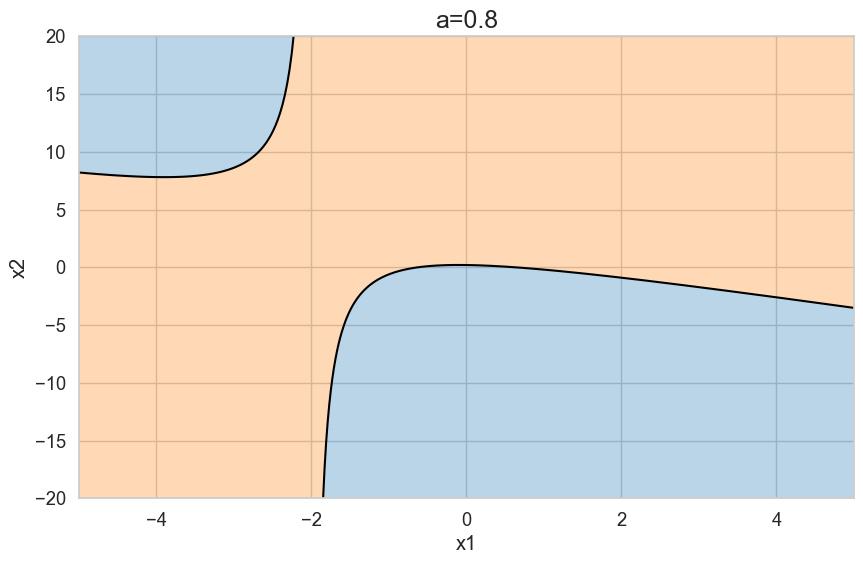

In [47]:
xs1 = np.linspace(-5, -2.01, 100)
xs2 = np.linspace(-1.99, 5, 700)

x1_values = np.linspace(-5, 5, 1000)
x2_values = np.linspace(-20, 20, 2000)

X1, X2 = np.meshgrid(x1_values, x2_values)
Z = 1 + 2 * X2 + X1 * X2 + X1 ** 2
H = 1 / (1 + np.exp(-Z))

for a in [0.2, 0.5, 0.8]:
    plt.contourf(X1, X2, H, levels=[0, a, 1], colors=["C0", "C1"], alpha=0.3)
    
    plt.plot(xs1, x2_val(xs1, a), color="black")
    plt.plot(xs2, x2_val(xs2, a), color="black")
    plt.xlim(-5, 5)
    plt.ylim(-20, 20)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"a={a}", fontsize=18)
    plt.show()

In [48]:
print("=== Пробные точки ===\n")

points_to_check = [(-4, 15), (-2, 0), (0, -10)]
a = 0.5
for pnt in points_to_check:
    print(f"Точка: {pnt}")
    x1, x2 = pnt
    z = z_val(x1, x2)
    h = sigmoid(z)
    sign = ">" if h > a else "<"
    bin_class = 1 if h > a else 0
    print(f"h(z) {sign} a ==> Класс {bin_class}\n")

=== Пробные точки ===

Точка: (-4, 15)
h(z) < a ==> Класс 0

Точка: (-2, 0)
h(z) > a ==> Класс 1

Точка: (0, -10)
h(z) < a ==> Класс 0



# 3D-график

<IPython.core.display.Javascript object>


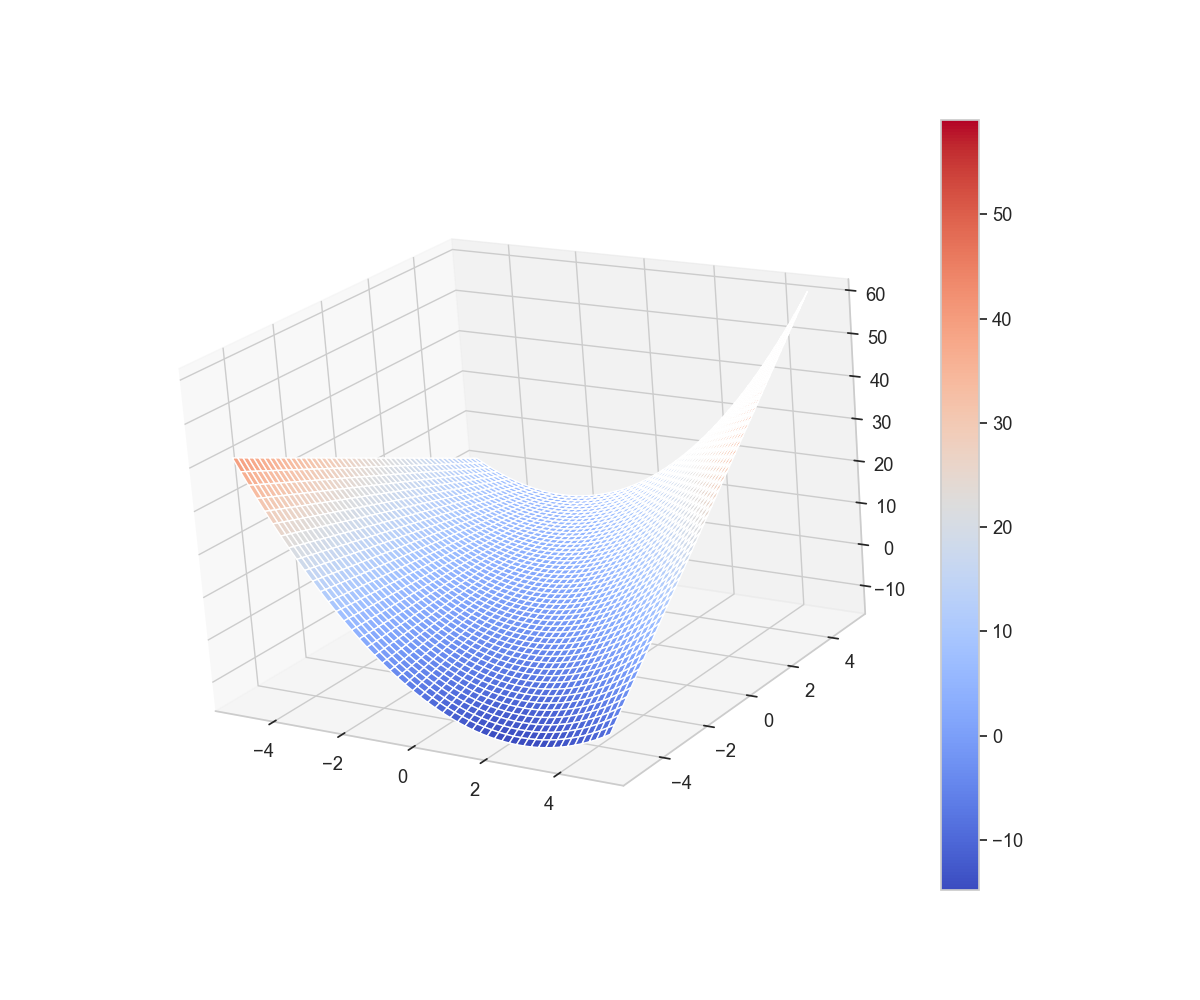

In [50]:
%matplotlib notebook
x1_values = np.linspace(-5, 5, 500)
x2_values = np.linspace(-5, 5, 500)
X1, X2 = np.meshgrid(x1_values, x2_values)

Z = z_val(X1, X2)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X1, X2, Z, cmap="coolwarm")
fig.colorbar(surf)
plt.show()